In [1]:
# ==========================================================
# 1. IMPORTS AND CONFIGURATION
# ==========================================================

from pathlib import Path
from collections import Counter
import hashlib
import json
import random
import re
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bs4 import BeautifulSoup
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

RUN_TOPIC_FINETUNING = True
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_PATH = Path(
    "/kaggle/input/datasets/"
    "abdelilehlouhichi/doj-releases/releases_merged.json"
)

OUTPUT_DIR = Path("/kaggle/working")
FIG_DIR = OUTPUT_DIR / "figs"
MODEL_DIR = OUTPUT_DIR / "topic_distilbert"

FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

EXPECTED_SHA256 = (
    "d4f7fe58e46cf1b7c93e18f3064f1b1dfebdca12f5f6647a6f7d9d776d29e461"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

print("Dataset:", DATA_PATH)

Dataset: /kaggle/input/datasets/abdelilehlouhichi/doj-releases/releases_merged.json


In [2]:
# ==========================================================
# 2. VERIFY AND LOAD DATA
# ==========================================================

def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()


actual_sha256 = sha256_file(DATA_PATH)

print("Expected SHA-256:", EXPECTED_SHA256)
print("Actual SHA-256:  ", actual_sha256)

if actual_sha256 != EXPECTED_SHA256:
    raise RuntimeError(
        "SHA-256 mismatch. The dataset is not the expected frozen snapshot."
    )

with open(DATA_PATH, "r", encoding="utf-8") as file:
    raw_records = json.load(file)

if isinstance(raw_records, dict):
    raw_records = raw_records["records"]

df = pd.DataFrame(raw_records)

print("Raw records:", len(df))
print("Raw columns:", list(df.columns))

Expected SHA-256: d4f7fe58e46cf1b7c93e18f3064f1b1dfebdca12f5f6647a6f7d9d776d29e461
Actual SHA-256:   d4f7fe58e46cf1b7c93e18f3064f1b1dfebdca12f5f6647a6f7d9d776d29e461
Raw records: 31450
Raw columns: ['attachment', 'body', 'changed', 'component', 'created', 'date', 'image', 'number', 'teaser', 'title', 'topic', 'url', 'uuid']


In [4]:
# ==========================================================
# 3. CLEANING FUNCTIONS
# ==========================================================

def clean_html(value):
    if value is None:
        return ""

    value = str(value)

    soup = BeautifulSoup(value, "html.parser")

    for element in soup(["script", "style", "noscript"]):
        element.decompose()

    text = soup.get_text(" ", strip=True)
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def flatten_names(value):
    if value is None:
        return ""

    if isinstance(value, str):
        return value.strip()

    if not isinstance(value, list):
        return str(value).strip()

    names = []

    for item in value:
        if isinstance(item, dict) and item.get("name"):
            names.append(str(item["name"]).strip())
        elif isinstance(item, str) and item.strip():
            names.append(item.strip())

    return " | ".join(dict.fromkeys(names))


def parse_unix_date(value):
    try:
        timestamp = pd.to_numeric(value, errors="raise")
        return pd.to_datetime(timestamp, unit="s", utc=True)
    except (ValueError, TypeError, OverflowError):
        return pd.NaT

In [5]:
# ==========================================================
# 4. CLEAN, DEDUPLICATE AND REMOVE EMPTY BODIES
# ==========================================================

clean = df.copy()

clean["title"] = (
    clean["title"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean["body_text"] = clean["body"].apply(clean_html)

clean["topic"] = clean["topic"].apply(flatten_names)
clean["office"] = clean["component"].apply(flatten_names)

clean["date"] = clean["date"].apply(parse_unix_date)
clean["date_iso"] = clean["date"].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
clean["year_month"] = clean["date"].dt.strftime("%Y-%m")

clean["url"] = (
    clean["url"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean["uuid"] = (
    clean["uuid"]
    .fillna("")
    .astype(str)
    .str.strip()
)

clean["body_chars"] = clean["body_text"].str.len()

# Remove duplicate records using UUID
before_deduplication = len(clean)

clean = clean.drop_duplicates(
    subset="uuid",
    keep="first"
).copy()

# Remove records with empty body text
clean = clean[
    clean["body_text"].str.strip() != ""
].copy()

print("Records before deduplication:", before_deduplication)
print("Records after cleaning:", len(clean))
print("Empty body rows removed:", (clean["body_chars"] == 0).sum())
print("Duplicated UUIDs:", clean["uuid"].duplicated().sum())

Records before deduplication: 31450
Records after cleaning: 15573
Empty body rows removed: 0
Duplicated UUIDs: 0


In [6]:
# ==========================================================
# 5. DEFINE FRAUD RECORDS
# ==========================================================

clean["fraud_topic"] = clean["topic"].str.contains(
    r"\bfraud\b",
    case=False,
    regex=True,
    na=False,
)

clean["fraud_title"] = clean["title"].str.contains(
    r"\bfraud\b",
    case=False,
    regex=True,
    na=False,
)

fraud_mask = clean["fraud_topic"] | clean["fraud_title"]

print("Fraud records selected:", fraud_mask.sum())

Fraud records selected: 2878


In [7]:
# ==========================================================
# 6. FINE-TUNE DISTILBERT FOR MISSING TOPICS
# ==========================================================

if RUN_TOPIC_FINETUNING:

    import torch
    from torch.utils.data import Dataset, DataLoader

    try:
        from transformers import (
            AutoTokenizer,
            AutoModelForSequenceClassification,
            get_linear_schedule_with_warmup,
        )
    except ImportError:
        import subprocess
        import sys

        subprocess.check_call([
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "transformers",
        ])

        from transformers import (
            AutoTokenizer,
            AutoModelForSequenceClassification,
            get_linear_schedule_with_warmup,
        )

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    print("Training device:", device)

    labeled = clean[
        clean["topic"].str.strip() != ""
    ].copy()

    missing = clean[
        clean["topic"].str.strip() == ""
    ].copy()

    print("Rows with topics:", len(labeled))
    print("Rows with missing topics:", len(missing))

    topic_counter = Counter()

    for topic_string in labeled["topic"]:
        topic_counter.update([
            topic.strip()
            for topic in topic_string.split("|")
            if topic.strip()
        ])

    TOPIC_LABELS = [
        topic
        for topic, count in topic_counter.most_common(30)
        if count >= 20
    ]

    print("Number of topic labels:", len(TOPIC_LABELS))

    def get_topic_vector(topic_string):
        topics = {
            topic.strip()
            for topic in topic_string.split("|")
            if topic.strip()
        }

        return np.array(
            [
                1 if topic in topics else 0
                for topic in TOPIC_LABELS
            ],
            dtype=np.float32,
        )

    labeled["topic_vector"] = labeled["topic"].apply(
        get_topic_vector
    )

    train_df, validation_df = train_test_split(
        labeled,
        test_size=0.15,
        random_state=RANDOM_STATE,
    )

    MODEL_NAME = "distilbert-base-uncased"

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

    class TopicDataset(Dataset):
        def __init__(
            self,
            frame,
            tokenizer,
            max_length=256,
        ):
            self.texts = frame["body_text"].astype(str).tolist()

            self.labels = np.vstack(
                frame["topic_vector"].to_numpy()
            ).astype(np.float32)

            self.tokenizer = tokenizer
            self.max_length = max_length

        def __len__(self):
            return len(self.texts)

        def __getitem__(self, index):
            encoded = self.tokenizer(
                self.texts[index],
                truncation=True,
                padding="max_length",
                max_length=self.max_length,
                return_tensors="pt",
            )

            item = {
                key: value.squeeze(0)
                for key, value in encoded.items()
            }

            item["labels"] = torch.tensor(
                self.labels[index],
                dtype=torch.float32,
            )

            return item

    train_dataset = TopicDataset(
        train_df,
        tokenizer,
    )

    validation_dataset = TopicDataset(
        validation_df,
        tokenizer,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=8,
        shuffle=True,
    )

    validation_loader = DataLoader(
        validation_dataset,
        batch_size=16,
        shuffle=False,
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME,
        num_labels=len(TOPIC_LABELS),
        problem_type="multi_label_classification",
    )

    model.to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-5,
    )

    epochs = 2
    total_steps = len(train_loader) * epochs

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=max(1, int(total_steps * 0.1)),
        num_training_steps=total_steps,
    )

    loss_function = torch.nn.BCEWithLogitsLoss()

    model.train()

    for epoch in range(epochs):
        total_loss = 0.0

        for batch in train_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            optimizer.zero_grad()

            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
            )

            loss = loss_function(
                outputs.logits,
                batch["labels"],
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            optimizer.step()
            scheduler.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"loss={average_loss:.4f}"
        )

    # Validation
    model.eval()

    validation_predictions = []
    validation_targets = []

    with torch.no_grad():
        for batch in validation_loader:
            batch = {
                key: value.to(device)
                for key, value in batch.items()
            }

            logits = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"],
            ).logits

            probabilities = torch.sigmoid(logits).cpu().numpy()
            targets = batch["labels"].cpu().numpy()

            validation_predictions.append(probabilities)
            validation_targets.append(targets)

    validation_predictions = np.vstack(validation_predictions)
    validation_targets = np.vstack(validation_targets)

    threshold = 0.35

    validation_binary = (
        validation_predictions >= threshold
    ).astype(int)

    micro_f1 = f1_score(
        validation_targets,
        validation_binary,
        average="micro",
        zero_division=0,
    )

    macro_f1 = f1_score(
        validation_targets,
        validation_binary,
        average="macro",
        zero_division=0,
    )

    print("Validation micro-F1:", round(micro_f1, 4))
    print("Validation macro-F1:", round(macro_f1, 4))

    # Predict topics for rows with missing topics
    if len(missing) > 0:

        missing_predictions = []

        for start in range(0, len(missing), 16):
            batch_texts = missing["body_text"].iloc[
                start:start + 16
            ].tolist()

            encoded = tokenizer(
                batch_texts,
                truncation=True,
                padding=True,
                max_length=256,
                return_tensors="pt",
            )

            encoded = {
                key: value.to(device)
                for key, value in encoded.items()
            }

            with torch.no_grad():
                logits = model(
                    input_ids=encoded["input_ids"],
                    attention_mask=encoded["attention_mask"],
                ).logits

                probabilities = torch.sigmoid(
                    logits
                ).cpu().numpy()

            missing_predictions.append(probabilities)

        missing_predictions = np.vstack(
            missing_predictions
        )

        predicted_topics = []

        for probabilities in missing_predictions:
            selected = np.where(
                probabilities >= threshold
            )[0]

            if len(selected) == 0:
                selected = np.argsort(
                    probabilities
                )[-3:][::-1]

            selected = selected[
                np.argsort(probabilities[selected])[::-1]
            ][:3]

            topics = [
                TOPIC_LABELS[index]
                for index in selected
                if probabilities[index] >= 0.05
            ]

            predicted_topics.append(
                " | ".join(topics)
            )

        # Fill ONLY empty topics.
        # Existing topics are not changed.
        for index, predicted_topic in zip(
            missing.index,
            predicted_topics,
        ):
            if predicted_topic.strip():
                clean.loc[index, "topic"] = predicted_topic

    model.save_pretrained(MODEL_DIR)
    tokenizer.save_pretrained(MODEL_DIR)

    print("Fine-tuning completed.")

Training device: cuda
Rows with topics: 13277
Rows with missing topics: 2296
Number of topic labels: 30


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (2 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2, loss=0.1769
Epoch 2/2, loss=0.0827
Validation micro-F1: 0.6762
Validation macro-F1: 0.37


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning completed.


In [8]:
# ==========================================================
# 7. CREATE THE FINAL RELEASE DATASET
# ==========================================================

# Remove any empty topic that could not receive a prediction
# without inventing a topic.
clean["topic"] = (
    clean["topic"]
    .fillna("not stated")
    .astype(str)
    .str.strip()
)

clean.loc[
    clean["topic"] == "",
    "topic"
] = "not stated"

# Keep only useful project columns.
# The requested unnecessary columns are excluded.
release_columns = [
    "uuid",
    "title",
    "date_iso",
    "year_month",
    "body_text",
    "topic",
    "office",
    "url",
    "body_chars",
]

releases_final = clean[release_columns].copy()

# Replace all remaining missing values
releases_final = releases_final.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

releases_final = releases_final.fillna("not stated")

# Final duplicate protection
releases_final = releases_final.drop_duplicates(
    subset="uuid",
    keep="first"
)

releases_final.to_csv(
    OUTPUT_DIR / "releases_final.csv",
    index=False,
)

print("Saved: releases_final.csv")

Saved: releases_final.csv


In [17]:
# ==========================================================
# CREATE THE FINAL FRAUD DATASET
# ==========================================================

# Keep only rows where:
# topic contains "fraud" OR title contains "fraud"
fraud_selection = fraud_mask.reindex(
    releases_final.index,
    fill_value=False,
)

fraud_final = releases_final.loc[
    fraud_selection
].copy()

fraud_final = fraud_final.drop_duplicates(
    subset="uuid",
    keep="first",
)

fraud_final.to_csv(
    OUTPUT_DIR / "fraud_selected_final.csv",
    index=False,
)

print("Saved: fraud_selected_final.csv")
print("Fraud rows:", len(fraud_final))

Saved: fraud_selected_final.csv
Fraud rows: 2878


In [10]:
# ==========================================================
# 9. CREATE THE FINAL FACTS SHEET
# ==========================================================

amount_pattern = re.compile(
    r"\$[\d][\d,]*(?:\.\d+)?"
    r"(?:\s*(?:million|billion|thousand))?",
    flags=re.IGNORECASE,
)

date_pattern = re.compile(
    r"\b(?:January|February|March|April|May|June|July|"
    r"August|September|October|November|December)"
    r"\s+\d{1,2},\s+\d{4}\b"
)

stage_pattern = re.compile(
    r"\b(?:indicted|charged|pleaded guilty|pleads guilty|"
    r"guilty|convicted|sentenced|arraigned|arrested|"
    r"awaiting sentencing)\b",
    flags=re.IGNORECASE,
)


def unique_matches(pattern, text):
    matches = pattern.findall(str(text))
    return " | ".join(dict.fromkeys(matches))


facts_pool = fraud_final[
    (fraud_final["body_chars"] >= 800)
    & (fraud_final["body_chars"] <= 4000)
    & fraud_final["body_text"].str.contains(
        r"\$",
        regex=True,
        na=False,
    )
].copy()

facts_final = facts_pool.sample(
    n=min(30, len(facts_pool)),
    random_state=RANDOM_STATE,
).copy()

facts_final["amounts_found"] = facts_final[
    "body_text"
].apply(
    lambda text: unique_matches(
        amount_pattern,
        text,
    )
)

facts_final["dates_found"] = facts_final[
    "body_text"
].apply(
    lambda text: unique_matches(
        date_pattern,
        text,
    )
)

facts_final["stages_found"] = facts_final[
    "body_text"
].apply(
    lambda text: unique_matches(
        stage_pattern,
        text,
    )
)

facts_columns = [
    "uuid",
    "title",
    "date_iso",
    "office",
    "topic",
    "url",
    "body_chars",
    "amounts_found",
    "dates_found",
    "stages_found",
    "body_text",
]

facts_final = facts_final[facts_columns].copy()

facts_final = facts_final.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

facts_final = facts_final.fillna("not stated")

facts_final.to_csv(
    OUTPUT_DIR / "facts_sheet_final.csv",
    index=False,
)

print("Saved: facts_sheet_final.csv")

Saved: facts_sheet_final.csv


In [18]:
# ==========================================================
# 10. FINAL VALIDATION
# ==========================================================

def validate_final_file(path):
    data = pd.read_csv(path)

    missing_values = data.isna().sum().sum()

    empty_values = (
        data.astype(str)
        .apply(lambda column: column.str.strip().eq("").sum())
        .sum()
    )

    duplicate_uuids = data["uuid"].duplicated().sum()

    print(f"\nFile: {path.name}")
    print("Rows:", len(data))
    print("Columns:", len(data.columns))
    print("Missing values:", missing_values)
    print("Empty values:", empty_values)
    print("Duplicate UUIDs:", duplicate_uuids)
    print("Column names:", list(data.columns))


validate_final_file(OUTPUT_DIR / "releases_final.csv")
validate_final_file(OUTPUT_DIR / "fraud_selected_final.csv")
validate_final_file(OUTPUT_DIR / "facts_sheet_final.csv")


File: releases_final.csv
Rows: 15573
Columns: 9
Missing values: 0
Empty values: 0
Duplicate UUIDs: 0
Column names: ['uuid', 'title', 'date_iso', 'year_month', 'body_text', 'topic', 'office', 'url', 'body_chars']

File: fraud_selected_final.csv
Rows: 2878
Columns: 9
Missing values: 0
Empty values: 0
Duplicate UUIDs: 0
Column names: ['uuid', 'title', 'date_iso', 'year_month', 'body_text', 'topic', 'office', 'url', 'body_chars']

File: facts_sheet_final.csv
Rows: 30
Columns: 11
Missing values: 0
Empty values: 0
Duplicate UUIDs: 0
Column names: ['uuid', 'title', 'date_iso', 'office', 'topic', 'url', 'body_chars', 'amounts_found', 'dates_found', 'stages_found', 'body_text']


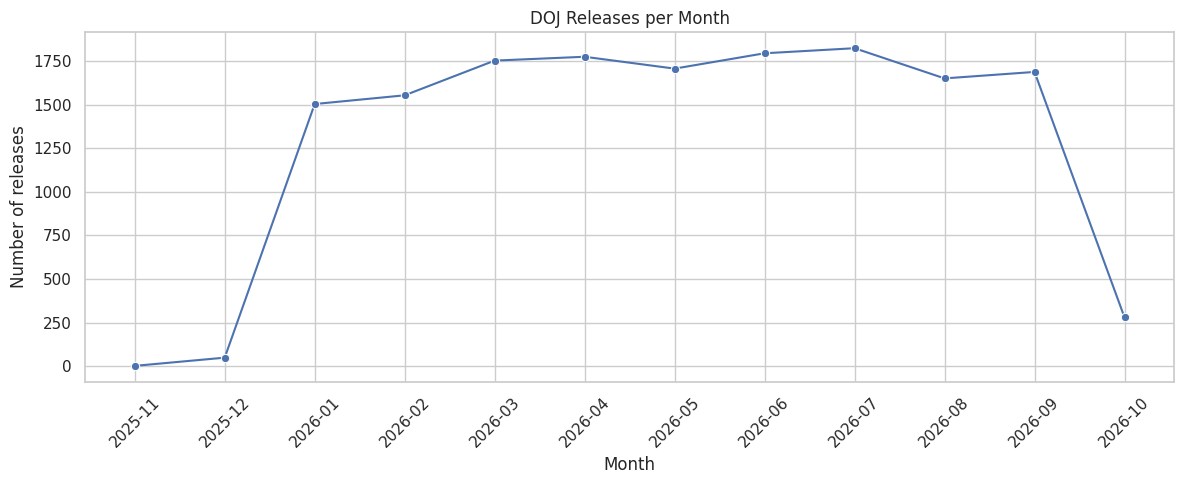

In [12]:
# ==========================================================
# EXPLORATORY DATA ANALYSIS
# Place this after fine-tuning
# ==========================================================

sns.set_theme(style="whitegrid")

# ----------------------------------------------------------
# 1. Monthly publication volume
# ----------------------------------------------------------

clean_valid = clean.dropna(subset=["date"]).copy()

monthly = (
    clean_valid
    .groupby("year_month")
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly,
    x="year_month",
    y="count",
    marker="o",
)

plt.xticks(rotation=45)
plt.title("DOJ Releases per Month")
plt.xlabel("Month")
plt.ylabel("Number of releases")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "monthly_volume.png",
    dpi=200,
)

plt.show()

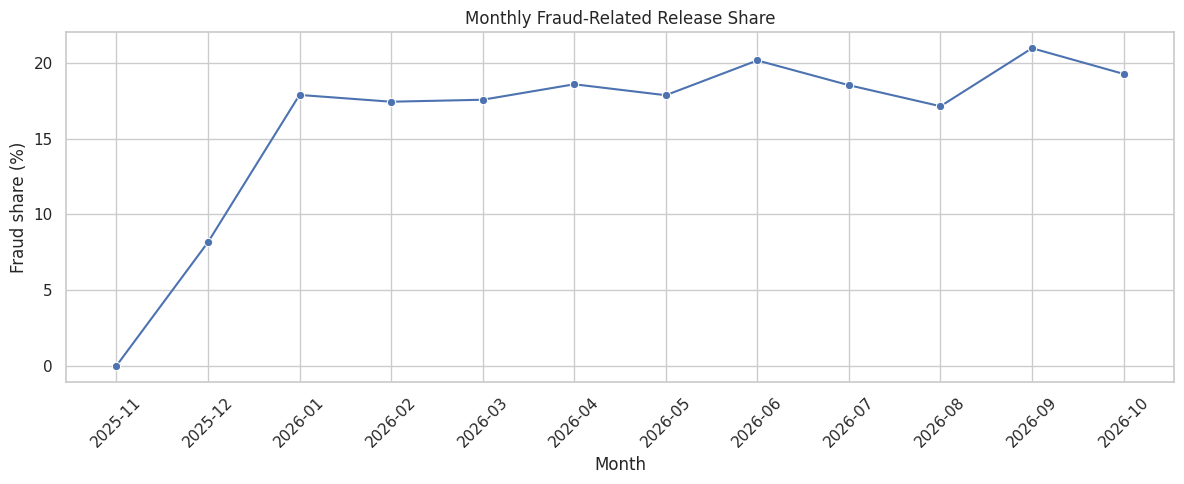

In [13]:
# ----------------------------------------------------------
# 2. Monthly fraud share
# ----------------------------------------------------------

# Use fraud_mask created before fine-tuning.
# It follows the data-card rule:
# topic contains "fraud" OR title contains "fraud".

clean_valid["is_fraud_related"] = fraud_mask.loc[
    clean_valid.index
].astype(int)

fraud_monthly = (
    clean_valid
    .groupby("year_month")
    .agg(
        total=("uuid", "count"),
        fraud=("is_fraud_related", "sum"),
    )
    .reset_index()
)

fraud_monthly["fraud_share"] = (
    fraud_monthly["fraud"]
    / fraud_monthly["total"]
    * 100
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=fraud_monthly,
    x="year_month",
    y="fraud_share",
    marker="o",
)

plt.xticks(rotation=45)
plt.title("Monthly Fraud-Related Release Share")
plt.xlabel("Month")
plt.ylabel("Fraud share (%)")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "fraud_share.png",
    dpi=200,
)

plt.show()

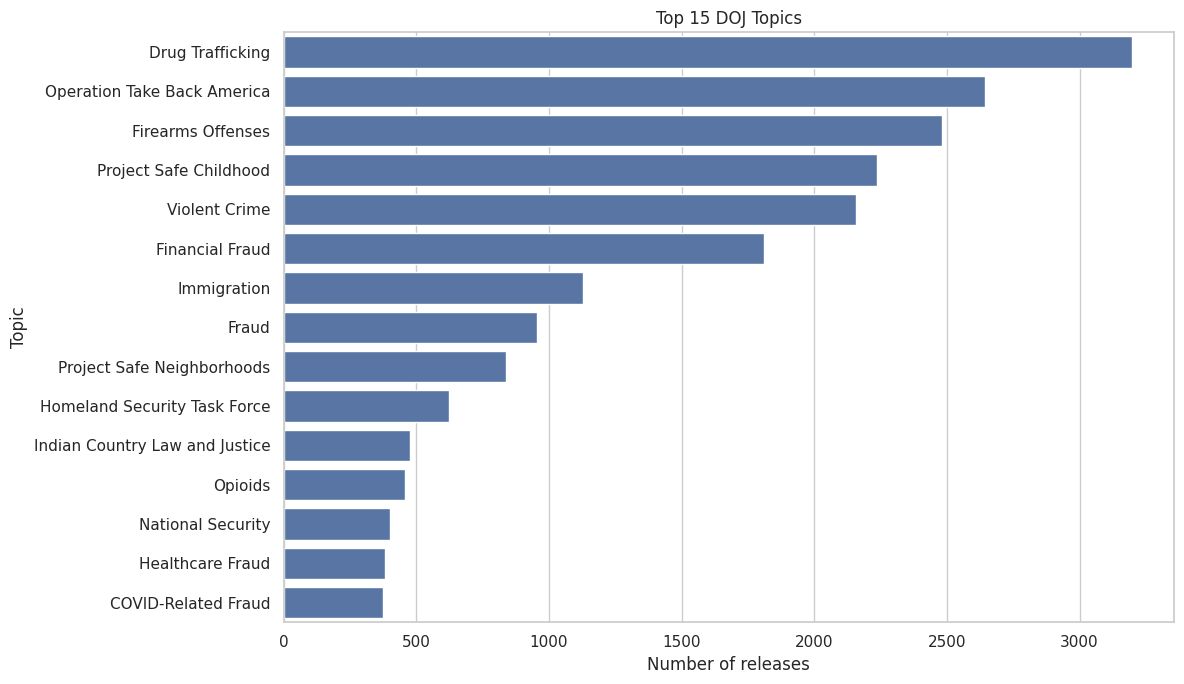

In [14]:
# ----------------------------------------------------------
# 3. Top topics
# ----------------------------------------------------------

topic_counts = Counter()

for topic_string in clean["topic"]:
    if topic_string and topic_string != "not stated":
        topic_counts.update(
            topic.strip()
            for topic in topic_string.split("|")
            if topic.strip()
        )

top_topics = pd.DataFrame(
    topic_counts.most_common(15),
    columns=["topic", "count"],
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_topics,
    y="topic",
    x="count",
)

plt.title("Top 15 DOJ Topics")
plt.xlabel("Number of releases")
plt.ylabel("Topic")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "top_topics.png",
    dpi=200,
)

plt.show()

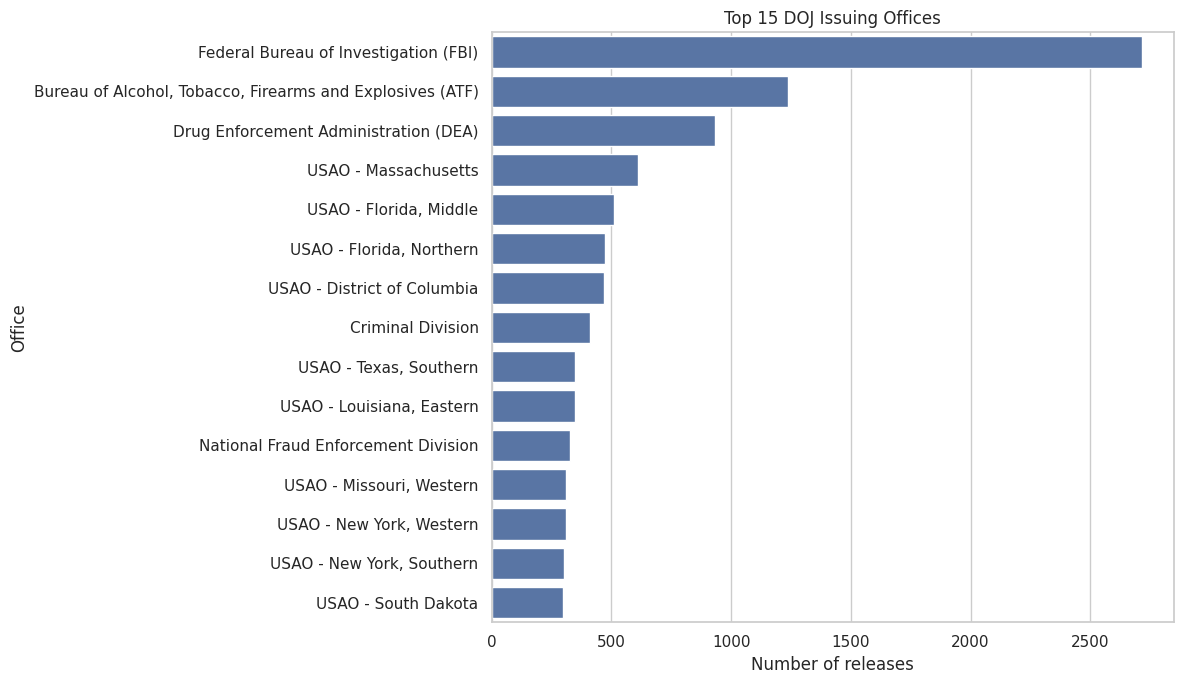

In [15]:
# ----------------------------------------------------------
# 4. Top issuing offices
# ----------------------------------------------------------

office_counts = Counter()

for office_string in clean["office"]:
    if office_string and office_string != "not stated":
        office_counts.update(
            office.strip()
            for office in office_string.split("|")
            if office.strip()
        )

top_offices = pd.DataFrame(
    office_counts.most_common(15),
    columns=["office", "count"],
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_offices,
    y="office",
    x="count",
)

plt.title("Top 15 DOJ Issuing Offices")
plt.xlabel("Number of releases")
plt.ylabel("Office")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "top_offices.png",
    dpi=200,
)

plt.show()

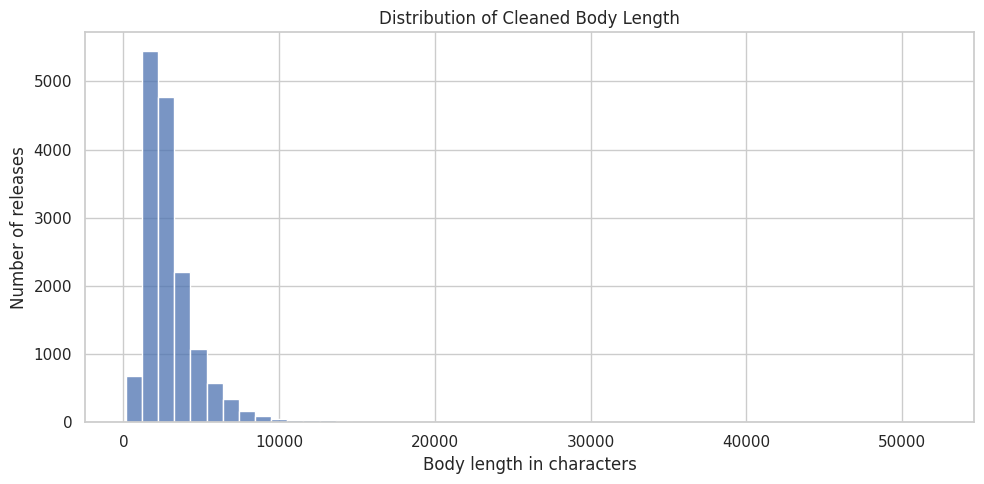

In [16]:
# ----------------------------------------------------------
# 5. Body-text length distribution
# ----------------------------------------------------------

plt.figure(figsize=(10, 5))

sns.histplot(
    data=clean,
    x="body_chars",
    bins=50,
)

plt.title("Distribution of Cleaned Body Length")
plt.xlabel("Body length in characters")
plt.ylabel("Number of releases")
plt.tight_layout()

plt.savefig(
    FIG_DIR / "body_length_distribution.png",
    dpi=200,
)

plt.show()